In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
from scipy.optimize import curve_fit

In [6]:
data = pd.read_csv("~/PythonDecal/leah/noisy_curvefit_data.csv")
df = pd.DataFrame(data)
df

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113
...,...,...,...,...,...,...
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548


In [10]:
df.shape

(100, 6)

In [11]:
#There are 100 rows and 6 columns

In [12]:
df.head()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [14]:
df.tail()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [15]:
df.columns.tolist()

['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']

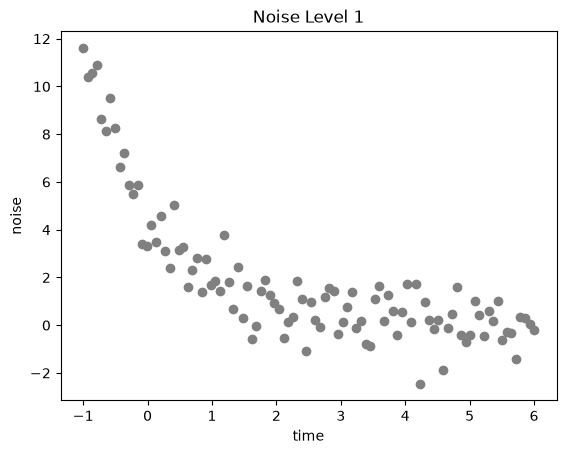

In [58]:
x = df.iloc[:,0]
y_noise_1 = df.iloc[:,1]
plt.scatter(x, y_noise_1, c='gray')
plt.xlabel('time')
plt.ylabel('noise')
plt.title('Noise Level 1')
plt.show()

In [133]:
def model(x, A, k):
    return A * np.exp(-k * x)
    
p0 = [1,1]
popt, pcov = curve_fit(model, x, y_noise_3, p0=p0)
A_fit, k_fit = popt
f"Fit: y = {A_fit: .2f} * e ^(-{k_fit: .2f} * x)"

'Fit: y =  5.06 * e ^(- 0.73 * x)'

In [132]:
residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof
chi2_reduced

np.float64(0.7906732087457324)

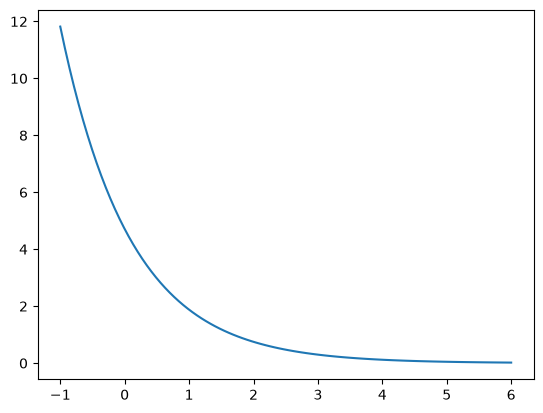

In [67]:
y = 4.71 * np.e ** (- 0.92 * x)
plt.plot(x, y)

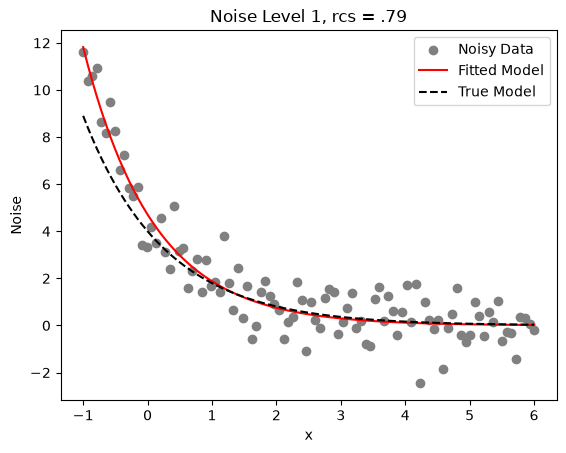

In [104]:
x = df.iloc[:,0]
y_noise_1 = df.iloc[:,1]
plt.scatter(x, y_noise_1, c='gray', label = 'Noisy Data')
plt.xlabel('x')
plt.ylabel('Noise')
plt.title('Noise Level 1, rcs = .79')

y = 4.71 * np.e ** (- 0.92 * x)
plt.plot(x, y, c = 'red', label = 'Fitted Model')

true_mod = model(x, 4, .8)
true_line = plt.plot(x, true_mod, c = 'black', linestyle = "--", label = 'True Model')

plt.legend()
plt.show()

In [129]:
ycolumns = df.iloc[:,1::]
def fit_model(x,y):
        p0 = [1,1]
        popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)
        A_fit, k_fit = popt
        residuals = y_noise_1 - model(x, A_fit, k_fit)
        chi2 = np.sum(residuals**2)
        dof = len(x) - len(popt)
        chi2_reduced = chi2 / dof
        return f"Fit: y = {A_fit: .2f} * e ^(-{k_fit: .2f} * x)", chi2_reduced
fit_model(x,y_noise_3)

NameError: name 'y_noise_3' is not defined

/var/folders/fm/jr7c_lqj23l5vfn4lpzhw3n40000gn/T/ipykernel_93112/491927055.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


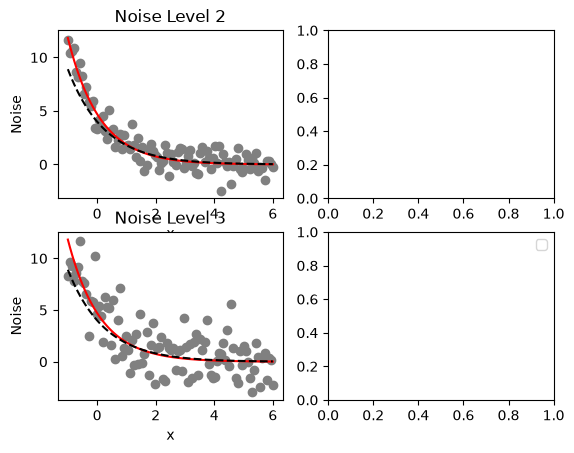

In [130]:
fig,ax = plt.subplots(2,2)

x = df.iloc[:,0]
y_noise_2 = df.iloc[:,1]
ax[0,0].scatter(x, y_noise_2, c='gray', label = 'Noisy Data')
ax[0,0].set_xlabel('x')
ax[0,0].set_ylabel('Noise')
ax[0,0].set_title('Noise Level 2')

y = 4.71 * np.e ** (- 0.92 * x)
ax[0,0].plot(x, y, c = 'red', label = 'Fitted Model')

true_mod = model(x, 4, .8)
true_line = ax[0,0].plot(x, true_mod, c = 'black', linestyle = "--", label = 'True Model')

x = df.iloc[:,0]
y_noise_3 = df.iloc[:,2]
ax[1,0].scatter(x, y_noise_3, c='gray', label = 'Noisy Data')
ax[1,0].set_xlabel('x')
ax[1,0].set_ylabel('Noise')
ax[1,0].set_title('Noise Level 3')

y = 4.71 * np.e ** (- 0.92 * x)
ax[1,0].plot(x, y, c = 'red', label = 'Fitted Model')

true_mod = model(x, 4, .8)
true_line = ax[1,0].plot(x, true_mod, c = 'black', linestyle = "--", label = 'True Model')






plt.legend()
plt.show()